In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col
import os

In [3]:

os.environ["PYSPARK_SUBMIT_ARGS"] = "--driver-memory 8g --executor-memory 8g pyspark-shell"

spark = SparkSession.builder \
    .appName("Colab_Optimized") \
    .master("local[*]") \
    .config("spark.driver.memory", "8g") \
    .config("spark.executor.memory", "8g") \
    .config("spark.sql.shuffle.partitions", "4") \
    .config("spark.default.parallelism", "4") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true") \
    .getOrCreate()

In [4]:
caminho_entrada = f'/content/drive/MyDrive/AmostraDS/amostra.csv'

In [5]:
schema_ddl  = "CD_IBGE_CADASTRO BIGINT, CO_FAMILIAR_FAM BIGINT, MARC_PBF INT, CO_CHV_NATURAL_PESSOA INT, IN_TRABALHO_INFANTIL_PESSOA BOOLEAN, CO_SEXO_PESSOA BYTE, DT_NASC_PESSOA DATE, CO_PARENTESCO_RF_PESSOA BYTE, CO_RACA_COR_PESSOA BYTE, CO_DEFICIENCIA_MEMB BOOLEAN, CO_SABE_LER_ESCREVER_MEMB BOOLEAN, IN_FREQUENTA_ESCOLA_MEMB BYTE, CO_CURSO_FREQUENTA_MEMB BYTE, CO_ANO_SERIE_FREQUENTA_MEMB BYTE, CO_CURSO_FREQ_PESSOA_MEMB BYTE, CO_ANO_SERIE_FREQUENTOU_MEMB BYTE, CO_CONCLUIU_FREQUENTOU_MEMB BOOLEAN, CO_TRABALHOU_SEMANA_MEMB BOOLEAN, CO_AGRICULTURA_TRAB_MEMB BOOLEAN, VL_REMUNER_EMPREGO_MEMB INT, VL_RENDA_BRUTA_12_MESES_MEMB INT, VL_RENDA_DOACAO_MEMB INT, VL_RENDA_APOSENT_MEMB INT, VL_RENDA_SEGURO_DESEMP_MEMB INT, VL_RENDA_PENSAO_ALIMEN_MEMB INT, VL_RENDA_OUTRAS_MEMB INT"

In [6]:
df_cad = spark.read.csv(caminho_entrada, header=True, schema=schema_ddl)

In [7]:
print(df_cad.columns)

['CD_IBGE_CADASTRO', 'CO_FAMILIAR_FAM', 'MARC_PBF', 'CO_CHV_NATURAL_PESSOA', 'IN_TRABALHO_INFANTIL_PESSOA', 'CO_SEXO_PESSOA', 'DT_NASC_PESSOA', 'CO_PARENTESCO_RF_PESSOA', 'CO_RACA_COR_PESSOA', 'CO_DEFICIENCIA_MEMB', 'CO_SABE_LER_ESCREVER_MEMB', 'IN_FREQUENTA_ESCOLA_MEMB', 'CO_CURSO_FREQUENTA_MEMB', 'CO_ANO_SERIE_FREQUENTA_MEMB', 'CO_CURSO_FREQ_PESSOA_MEMB', 'CO_ANO_SERIE_FREQUENTOU_MEMB', 'CO_CONCLUIU_FREQUENTOU_MEMB', 'CO_TRABALHOU_SEMANA_MEMB', 'CO_AGRICULTURA_TRAB_MEMB', 'VL_REMUNER_EMPREGO_MEMB', 'VL_RENDA_BRUTA_12_MESES_MEMB', 'VL_RENDA_DOACAO_MEMB', 'VL_RENDA_APOSENT_MEMB', 'VL_RENDA_SEGURO_DESEMP_MEMB', 'VL_RENDA_PENSAO_ALIMEN_MEMB', 'VL_RENDA_OUTRAS_MEMB']


In [8]:
df_cad.show()

+----------------+---------------+--------+---------------------+---------------------------+--------------+--------------+-----------------------+------------------+-------------------+-------------------------+------------------------+-----------------------+---------------------------+-------------------------+----------------------------+---------------------------+------------------------+------------------------+-----------------------+----------------------------+--------------------+---------------------+---------------------------+---------------------------+--------------------+
|CD_IBGE_CADASTRO|CO_FAMILIAR_FAM|MARC_PBF|CO_CHV_NATURAL_PESSOA|IN_TRABALHO_INFANTIL_PESSOA|CO_SEXO_PESSOA|DT_NASC_PESSOA|CO_PARENTESCO_RF_PESSOA|CO_RACA_COR_PESSOA|CO_DEFICIENCIA_MEMB|CO_SABE_LER_ESCREVER_MEMB|IN_FREQUENTA_ESCOLA_MEMB|CO_CURSO_FREQUENTA_MEMB|CO_ANO_SERIE_FREQUENTA_MEMB|CO_CURSO_FREQ_PESSOA_MEMB|CO_ANO_SERIE_FREQUENTOU_MEMB|CO_CONCLUIU_FREQUENTOU_MEMB|CO_TRABALHOU_SEMANA_MEMB|CO_AGRI

In [9]:
print ("a amostra possui ", df_cad.select("CD_IBGE_CADASTRO").distinct().count(), " municipios distintos")

a amostra possui  5570  municipios distintos


In [10]:
print( "sendo ", df_cad.filter(df_cad["CD_IBGE_CADASTRO"] == 3162500).count(), " de São joão del Rei")

sendo  9454  de São joão del Rei


In [11]:
df_cad.groupBy("CO_SEXO_PESSOA").count().show()

+--------------+-------+
|CO_SEXO_PESSOA|  count|
+--------------+-------+
|             2|4153746|
|             1|3218110|
+--------------+-------+



In [12]:
total_mulheres_rf = df_cad.filter(
    (df_cad["CO_SEXO_PESSOA"] == 2) &
    (df_cad["CO_PARENTESCO_RF_PESSOA"] == 1) &
    (df_cad["VL_REMUNER_EMPREGO_MEMB"] > 0)
).count()

In [13]:
total_mulheres_rf

811982

In [14]:
total_homens_rf = df_cad.filter(
    (df_cad["CO_SEXO_PESSOA"] == 1) &
    (df_cad["CO_PARENTESCO_RF_PESSOA"] == 1) &
    (df_cad["VL_REMUNER_EMPREGO_MEMB"] > 0)
).count()

In [15]:
total_homens_rf

180695

In [16]:
from pyspark.sql.functions import avg
df_cad.groupBy("CD_IBGE_CADASTRO", "CO_SEXO_PESSOA").agg(
    avg("VL_REMUNER_EMPREGO_MEMB").alias("media_renda")
).show()

+----------------+--------------+------------------+
|CD_IBGE_CADASTRO|CO_SEXO_PESSOA|       media_renda|
+----------------+--------------+------------------+
|         2107357|             1| 67.43793911007026|
|         2411601|             2|              94.6|
|         3550308|             2|335.48858440850444|
|         2505303|             1|59.127272727272725|
|         1702406|             1|128.69098712446353|
|         4314308|             1| 542.8478260869565|
|         2112407|             1|47.929597701149426|
|         4307708|             2|115.38682432432432|
|         3106200|             2|223.02146116149382|
|         2932457|             2| 66.92561983471074|
|         4101804|             1| 338.1098376313276|
|         2807204|             1| 92.25333333333333|
|         2614501|             1|48.579268292682926|
|         2917300|             1|106.87674418604651|
|         3300308|             1|213.52110625909754|
|         1505106|             1|144.516666666

In [17]:
from pyspark.sql.window import Window
from pyspark.sql.functions import avg


janela_sexo = Window.partitionBy("CO_SEXO_PESSOA")


df_cad_com_media = df_cad.withColumn(
    "MEDIA_RENDA_SEXO",
    avg("VL_REMUNER_EMPREGO_MEMB").over(janela_sexo)
)


df_cad_com_media.select("CO_SEXO_PESSOA", "VL_REMUNER_EMPREGO_MEMB", "MEDIA_RENDA_SEXO").show(10)

+--------------+-----------------------+-----------------+
|CO_SEXO_PESSOA|VL_REMUNER_EMPREGO_MEMB| MEDIA_RENDA_SEXO|
+--------------+-----------------------+-----------------+
|             2|                    954|148.2465598188438|
|             2|                      0|148.2465598188438|
|             2|                   NULL|148.2465598188438|
|             2|                      0|148.2465598188438|
|             2|                      0|148.2465598188438|
|             2|                    780|148.2465598188438|
|             2|                      0|148.2465598188438|
|             2|                      0|148.2465598188438|
|             2|                   NULL|148.2465598188438|
|             2|                      0|148.2465598188438|
+--------------+-----------------------+-----------------+
only showing top 10 rows


In [18]:
df_cad_com_media = df_cad_com_media.withColumn(
    "DIFERENCA_RENDA_MEDIA",
    col("VL_REMUNER_EMPREGO_MEMB") - col("MEDIA_RENDA_SEXO")
)

df_cad_com_media.select(
    "CO_SEXO_PESSOA",
    "VL_REMUNER_EMPREGO_MEMB",
    "MEDIA_RENDA_SEXO",
    "DIFERENCA_RENDA_MEDIA"
).show(10)

+--------------+-----------------------+-----------------+---------------------+
|CO_SEXO_PESSOA|VL_REMUNER_EMPREGO_MEMB| MEDIA_RENDA_SEXO|DIFERENCA_RENDA_MEDIA|
+--------------+-----------------------+-----------------+---------------------+
|             2|                    954|148.2465598188438|    805.7534401811562|
|             2|                      0|148.2465598188438|   -148.2465598188438|
|             2|                   NULL|148.2465598188438|                 NULL|
|             2|                      0|148.2465598188438|   -148.2465598188438|
|             2|                      0|148.2465598188438|   -148.2465598188438|
|             2|                    780|148.2465598188438|    631.7534401811562|
|             2|                      0|148.2465598188438|   -148.2465598188438|
|             2|                      0|148.2465598188438|   -148.2465598188438|
|             2|                   NULL|148.2465598188438|                 NULL|
|             2|            

In [19]:
import pandas as pd

df_pandas = df_cad.select(
"DT_NASC_PESSOA",
"CO_SEXO_PESSOA",
"CO_RACA_COR_PESSOA",
"VL_RENDA_BRUTA_12_MESES_MEMB",
"VL_REMUNER_EMPREGO_MEMB",
"CO_CURSO_FREQ_PESSOA_MEMB",
"CO_ANO_SERIE_FREQUENTA_MEMB",
"CO_DEFICIENCIA_MEMB",
"CO_FAMILIAR_FAM",
"VL_RENDA_DOACAO_MEMB",
"VL_RENDA_APOSENT_MEMB",
"VL_RENDA_SEGURO_DESEMP_MEMB",
"VL_RENDA_PENSAO_ALIMEN_MEMB",
"VL_RENDA_OUTRAS_MEMB",
"CD_IBGE_CADASTRO",
"CO_CURSO_FREQUENTA_MEMB",
"CO_PARENTESCO_RF_PESSOA",
"CO_CHV_NATURAL_PESSOA",
).toPandas()

import matplotlib.pyplot as mp
import seaborn as sb

# Etapa 1: Análise demográfica e mercado de trabalho

Questão 1

In [20]:
df_pandas["DT_NASC_PESSOA"] = pd.to_datetime(df_pandas["DT_NASC_PESSOA"], errors="coerce")
dataAtual = pd.Timestamp("2018-06-01")

df_pandas["IDADE"] = (dataAtual.year - df_pandas["DT_NASC_PESSOA"].dt.year -
((df_pandas["DT_NASC_PESSOA"].dt.month > dataAtual.month) |
 ((df_pandas["DT_NASC_PESSOA"].dt.month == dataAtual.month) & (df_pandas["DT_NASC_PESSOA"].dt.day > dataAtual.day))) )

df_pandas.loc[df_pandas["IDADE"] > 110, "IDADE"] = None

In [21]:
resultadoIdade = df_pandas.groupby(["CO_SEXO_PESSOA", "CO_RACA_COR_PESSOA"])["IDADE"].agg(["mean", "median", "std"])
resultadoIdade.columns = ["Media", "Mediana", "Desvio_Padrao"]
print(resultadoIdade)

                                       Media  Mediana  Desvio_Padrao
CO_SEXO_PESSOA CO_RACA_COR_PESSOA                                   
1              1.0                 27.022408     20.0      22.102589
               2.0                 31.140044     28.0      20.985049
               3.0                 26.739897     20.0      22.049055
               4.0                 24.995207     19.0      20.025204
               5.0                 20.492254     15.0      17.125525
2              1.0                 30.705862     28.0      21.430975
               2.0                 34.181035     33.0      19.106221
               3.0                 30.369697     28.0      20.383229
               4.0                 28.024229     25.0      19.255332
               5.0                 22.653668     19.0      16.851665


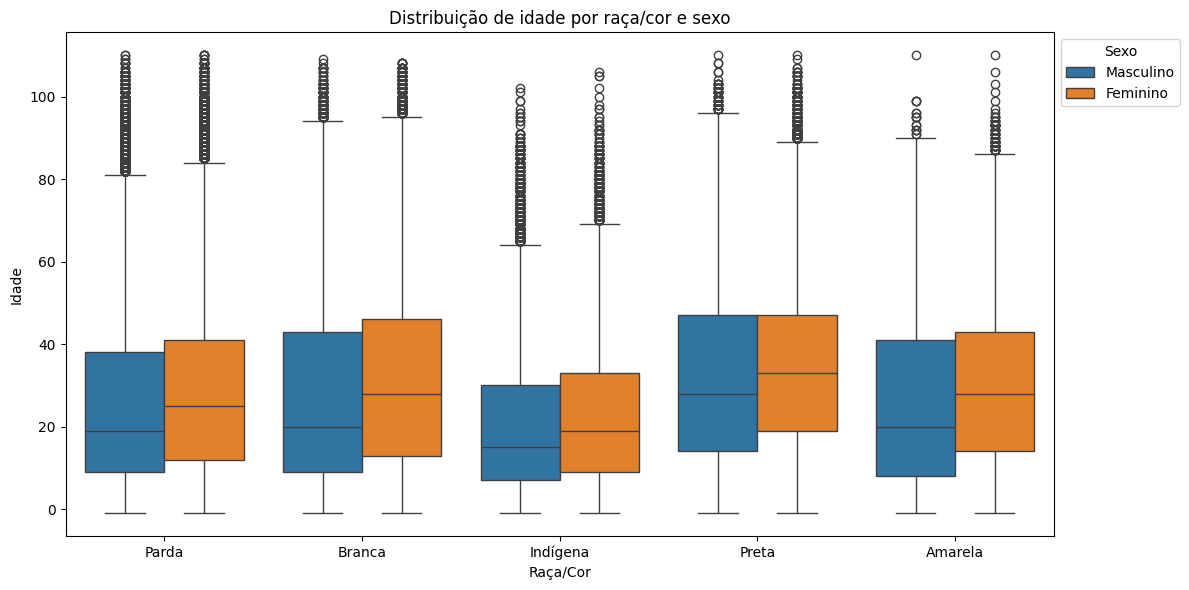

In [22]:
mapa_sexo = {
    1 : "Masculino",
    2 : "Feminino"
}
df_pandas["SEXO_SIGNIFICADO"] = df_pandas["CO_SEXO_PESSOA"].map(mapa_sexo)

mapa_raca_cor = {
    1 : "Branca",
    2 : "Preta",
    3 : "Amarela",
    4 : "Parda",
    5 : "Indígena",
}
df_pandas["COR_RACA_SIGNIFICADO"] = df_pandas["CO_RACA_COR_PESSOA"].map(mapa_raca_cor)

mp.figure(figsize = (12, 6))
grafico = sb.boxplot(data=df_pandas, x="COR_RACA_SIGNIFICADO", y="IDADE", hue="SEXO_SIGNIFICADO")
grafico.legend(title="Sexo", loc = "upper left", bbox_to_anchor = (1,1))
mp.xlabel("Raça/Cor")
mp.ylabel("Idade")
mp.title("Distribuição de idade por raça/cor e sexo")
mp.tight_layout()
mp.show()

Questão 2

In [32]:
condicoes = [
    ((df_pandas["VL_RENDA_BRUTA_12_MESES_MEMB"] != 0) & (df_pandas["VL_REMUNER_EMPREGO_MEMB"] == 0)),
    (df_pandas["VL_REMUNER_EMPREGO_MEMB"] != 0),
]

valores = [
    1,
    2,
]

df_pandas["FORMALIDADE_TRABALHO"] = np.select(condicoes, valores, default=0)

adultos = df_pandas[((df_pandas["IDADE"]>= 18) & (df_pandas["IDADE"]<=65) & df_pandas["FORMALIDADE_TRABALHO"].isin([1, 2]))]

qtd_informais = (adultos["FORMALIDADE_TRABALHO"] == 1).sum()
qtd_formais = (adultos["FORMALIDADE_TRABALHO"] == 2).sum()

total_trabalhadores = qtd_informais + qtd_formais

taxa_informais = (qtd_informais / total_trabalhadores)*100
taxa_formais = (qtd_formais / total_trabalhadores)*100

print (pd.DataFrame({
    "Tipo de Trabalhador" : ["Informal", "Formal"],
    "Quantidade": [qtd_informais, qtd_formais],
    "Taxa (%)": [taxa_informais, taxa_formais]
}))


  Tipo de Trabalhador  Quantidade   Taxa (%)
0            Informal     2438697  60.179109
1              Formal     1613701  39.820891


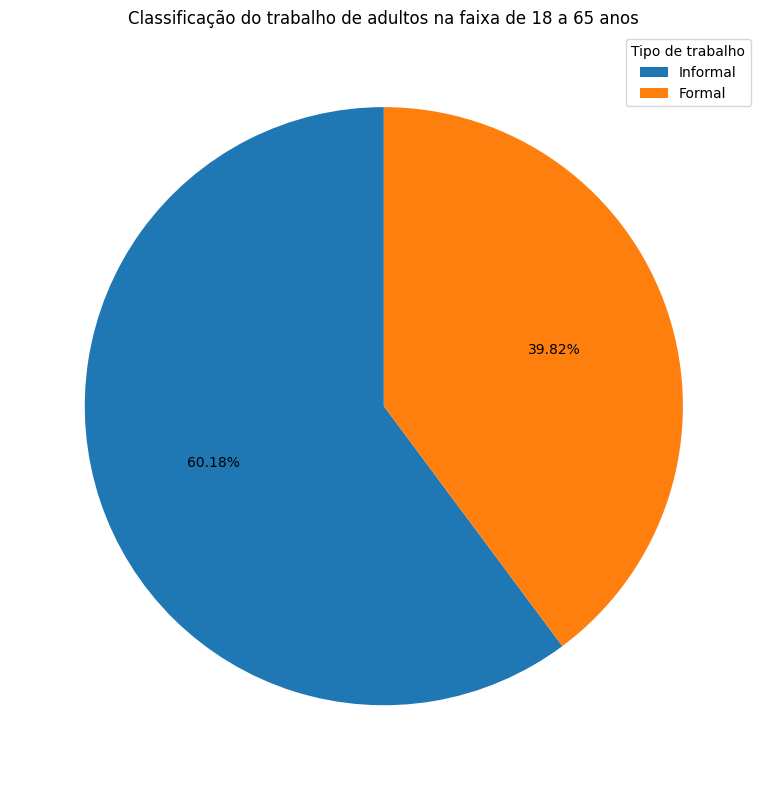

In [44]:
mapa_class_trabalho = {
    1 : "Informal",
    2 : "Formal"
}

contagem = adultos["FORMALIDADE_TRABALHO"].map(mapa_class_trabalho).value_counts()

mp.figure(figsize = (8, 8))
mp.pie (
    contagem.values,
    labels = None,
    autopct="%1.2f%%",
    startangle=90
)
mp.title("Classificação do trabalho de adultos na faixa de 18 a 65 anos")
mp.legend(contagem.index, title="Tipo de trabalho")
mp.tight_layout()
mp.show()

Questão 3

In [24]:
import numpy as np

condicoes = [
    df_pandas["CO_CURSO_FREQ_PESSOA_MEMB"].isin([1, 2, 3]),
    df_pandas["CO_CURSO_FREQ_PESSOA_MEMB"].isin([4, 5, 6, 7, 10, 11]),
    df_pandas["CO_CURSO_FREQ_PESSOA_MEMB"].isin([8, 9, 12]),
    df_pandas["CO_CURSO_FREQ_PESSOA_MEMB"] == 13,
    df_pandas["CO_CURSO_FREQ_PESSOA_MEMB"] == 14,
    df_pandas["CO_CURSO_FREQ_PESSOA_MEMB"] == 15,
]

valores = [
    "Educação Infantil",
    "Ensino Fundamental",
    "Ensino Médio",
    "Ensino Superior",
    "Alfabetização de Adultos",
    "Sem Escolaridade",
]

df_pandas["NIVEL_ESCOLARIDADE"] = np.select(
    condicoes,
    valores,
    default = "Não informado"
)

condicoes_frequenta = [
    df_pandas["CO_CURSO_FREQUENTA_MEMB"].isin([1, 2, 3]),
    df_pandas["CO_CURSO_FREQUENTA_MEMB"].isin([4, 5, 6, 9, 10]),
    df_pandas["CO_CURSO_FREQUENTA_MEMB"].isin([7, 8, 11]),
    df_pandas["CO_CURSO_FREQUENTA_MEMB"] == 13,
    df_pandas["CO_CURSO_FREQUENTA_MEMB"] == 12,
    df_pandas["CO_CURSO_FREQUENTA_MEMB"] == 14,
]

nivel_esc_atual = np.select(
    condicoes_frequenta,
    valores,
    default=None,
)

estuda_agora = df_pandas["CO_CURSO_FREQUENTA_MEMB"].notna()

df_pandas.loc[estuda_agora, "NIVEL_ESCOLARIDADE"] = nivel_esc_atual[estuda_agora]

resultado = df_pandas.groupby("NIVEL_ESCOLARIDADE").agg(
    Renda_Media = ("VL_REMUNER_EMPREGO_MEMB", "mean")
)

print (resultado)


                          Renda_Media
NIVEL_ESCOLARIDADE                   
Alfabetização de Adultos    76.005329
Educação Infantil           64.630704
Ensino Fundamental         147.116145
Ensino Médio               223.439581
Ensino Superior            571.264252
Não informado               61.635183
Sem Escolaridade           122.414775


# Etapa 2: Análise do perfil de trabalho e escolaridade

Questão 1

In [25]:
condicoes = [
    df_pandas["IDADE"].between(1, 12),
    df_pandas["IDADE"].between(13, 17),
    df_pandas["IDADE"].between(18, 29),
    df_pandas["IDADE"].between(30, 59),
    df_pandas["IDADE"]>=60
]

valores = [
    "Criança",
    "Adolescente",
    "Jovem",
    "Adulto",
    "Idoso"
]

df_pandas["FAIXA_ETARIA"] = np.select(
    condicoes,
    valores,
    default = "Não declarado"
)

In [26]:
resultado = df_pandas.groupby("FAIXA_ETARIA").agg(
    TOTAL = ("FAIXA_ETARIA", "size"),
    POSSUI_TRABALHO  = ("VL_REMUNER_EMPREGO_MEMB", lambda x : (x > 0).sum())
)

resultado["PROPORCAO (%)"] = (resultado["POSSUI_TRABALHO"] / resultado["TOTAL"]) * 100

print (resultado)


                 TOTAL  POSSUI_TRABALHO  PROPORCAO (%)
FAIXA_ETARIA                                          
Adolescente     818185             8763       1.071029
Adulto         2387351          1144435      47.937442
Criança        1938861                6       0.000309
Idoso           667137            66335       9.943235
Jovem          1402361           412079      29.384659
Não declarado   157961               66       0.041782


Questão 2

In [27]:
lista = [
    "VL_REMUNER_EMPREGO_MEMB",
    "VL_RENDA_APOSENT_MEMB",
    "VL_RENDA_SEGURO_DESEMP_MEMB",
    "VL_RENDA_PENSAO_ALIMEN_MEMB",
    "VL_RENDA_OUTRAS_MEMB",
]

df_pandas["RENDA_TOTAL"] = df_pandas[lista].fillna(0).sum(axis=1)

familias = (df_pandas.groupby("CO_FAMILIAR_FAM").agg(
    RENDA_FAMILIAR = ("RENDA_TOTAL", "sum"),
    NUM_MEMBROS_FAMILIA = ("RENDA_TOTAL", "size"),
)).reset_index()

familias["RENDA_PER_CAPITA"] = familias["RENDA_FAMILIAR"] / familias["NUM_MEMBROS_FAMILIA"]

salario_min = 954

condicoes = [
    familias["RENDA_PER_CAPITA"] <= 109,
    familias["RENDA_PER_CAPITA"] <= 218,
    familias["RENDA_PER_CAPITA"] <= (salario_min/2),
    familias["RENDA_PER_CAPITA"] > (salario_min/2),
]

valores = [
    1,
    2,
    3,
    4,
]

familias["CLASS_FAIXA_RENDA_FAM"] = np.select(
    condicoes,
    valores,
    default = 0,
)

df_pandas = df_pandas.merge(familias[["CO_FAMILIAR_FAM", "RENDA_PER_CAPITA", "CLASS_FAIXA_RENDA_FAM"]], on="CO_FAMILIAR_FAM")

numDeficientes = df_pandas[df_pandas["CO_DEFICIENCIA_MEMB"] == 1].groupby("CLASS_FAIXA_RENDA_FAM").size()
numTotalPorFaixa = familias.groupby("CLASS_FAIXA_RENDA_FAM")["NUM_MEMBROS_FAMILIA"].sum()

percentual = (numDeficientes / numTotalPorFaixa) * 100

resultado = pd.DataFrame({
    "FAIXA_RENDA" : numDeficientes,
    "NUM_DEFICIENTES" : numDeficientes,
    "PORCENTAGEM" : percentual,
}).reset_index()

#OBS: aparentemente, a coluna "CO_DEFICIENCIA_MEMB" está sem valores. Devido a isso, não foi possível determinar a
#porcentagem de pessoas com deficiência por classe social.
print (resultado)


   CLASS_FAIXA_RENDA_FAM  FAIXA_RENDA  NUM_DEFICIENTES  PORCENTAGEM
0                      1          NaN              NaN          NaN
1                      2          NaN              NaN          NaN
2                      3          NaN              NaN          NaN
3                      4          NaN              NaN          NaN


# Perguntas

Questão 1

In [28]:
resultado = df_pandas.groupby(["CO_SEXO_PESSOA", "CO_RACA_COR_PESSOA"])["VL_REMUNER_EMPREGO_MEMB"].agg(["mean", "median"]).reset_index()
resultado.columns = ["Sexo", "Raca/Cor", "Média", "Mediana"]
print (resultado)

   Sexo  Raca/Cor       Média  Mediana
0     1       1.0  299.005642      0.0
1     1       2.0  224.588343      0.0
2     1       3.0  232.096215      0.0
3     1       4.0  192.168384      0.0
4     1       5.0  138.818058      0.0
5     2       1.0  177.972434      0.0
6     2       2.0  161.221649      0.0
7     2       3.0  164.586873      0.0
8     2       4.0  133.239748      0.0
9     2       5.0   87.636597      0.0


Questão 2

In [29]:
renda_12_meses = df_pandas["VL_RENDA_BRUTA_12_MESES_MEMB"].fillna(0)
remuneracao_emprego = df_pandas["VL_REMUNER_EMPREGO_MEMB"].fillna(0)

condicoes = [
    (renda_12_meses != 0) & (remuneracao_emprego == 0),
    (remuneracao_emprego != 0),
]

valores = [
    1,
    2,
]

df_pandas["CLASS_TRABALHO"] = np.select(
    condicoes,
    valores,
    default=0,
)

percentual_informais = df_pandas[df_pandas["CLASS_TRABALHO"].isin([1, 2])].groupby("NIVEL_ESCOLARIDADE")["CLASS_TRABALHO"].apply(lambda x : (x == 1).sum() / (x.size) * 100)

print (percentual_informais)


NIVEL_ESCOLARIDADE
Alfabetização de Adultos    6.171491
Educação Infantil           4.239469
Ensino Fundamental          5.834679
Ensino Médio                7.139977
Ensino Superior             7.752777
Não informado               4.197883
Sem Escolaridade            4.600484
Name: CLASS_TRABALHO, dtype: float64


Questão 3

In [46]:
total_por_fx_etaria = df_pandas.groupby("FAIXA_ETARIA").size()
pcd_por_fx_etaria = df_pandas[df_pandas["CO_DEFICIENCIA_MEMB"] == 1].groupby("FAIXA_ETARIA")
qtd_pcd_por_fx_etaria = pcd_por_fx_etaria.size()

porcentagem_pcd_por_fx_etaria = (qtd_pcd_por_fx_etaria / total_por_fx_etaria) * 100

total_extrema_pobreza = (df_pandas[df_pandas["RENDA_PER_CAPITA"] <= 89].groupby("FAIXA_ETARIA"))
pcd_extrema_pobreza = (df_pandas[
    (df_pandas["CO_DEFICIENCIA_MEMB"] == 1) &
    (df_pandas["RENDA_PER_CAPITA"] <= 89)
].groupby("FAIXA_ETARIA"))

porcentagem_pcd_extrema_pobreza = ((pcd_extrema_pobreza.size()) / (qtd_pcd_por_fx_etaria)) * 100

resultado = pd.DataFrame({
    "Porcentagem_PCD_(%)" : porcentagem_pcd_por_fx_etaria,
    "Porcentagem_PCD_Extrema_Pobreza" : porcentagem_pcd_extrema_pobreza
}).reset_index()

print (resultado)

#OBS: As porcentagens não vão aparecer, pois a coluna com indicativos de PCD está vazia no dataset.



    FAIXA_ETARIA  Porcentagem_PCD_(%)  Porcentagem_PCD_Extrema_Pobreza
0    Adolescente                  NaN                              NaN
1         Adulto                  NaN                              NaN
2        Criança                  NaN                              NaN
3          Idoso                  NaN                              NaN
4          Jovem                  NaN                              NaN
5  Não declarado                  NaN                              NaN


Questão 4

In [ ]:
criancas_ate_6 = df_pandas[((df_pandas["IDADE"] >= 0) & (df_pandas["IDADE"] <= 6))]
filhos_do_rf = criancas_ate_6[criancas_ate_6["CO_PARENTESCO_RF_PESSOA"] == 3]

familias_com_criancas = filhos_do_rf["CO_FAMILIAR_FAM"].unique()
maes_rf = df_pandas[(
    (df_pandas["CO_FAMILIAR_FAM"].isin(familias_com_criancas)) &
    (df_pandas["CO_PARENTESCO_RF_PESSOA"] == 1) &
    (df_pandas["CO_SEXO_PESSOA"] == 2)
)]

m_rf_sem_criancas = df_pandas[(
    (df_pandas["CO_SEXO_PESSOA"] == 2) &
    (df_pandas["CO_PARENTESCO_RF_PESSOA"] == 1) &
    (~df_pandas["CO_CHV_NATURAL_PESSOA"].isin(maes_rf["CO_CHV_NATURAL_PESSOA"]))
)]

porcentagem_maes_rf = ((maes_rf["VL_REMUNER_EMPREGO_MEMB"] > 0).sum() / len(maes_rf)) * 100
porcentagem_m_rf_sem_criancas = ((m_rf_sem_criancas["VL_REMUNER_EMPREGO_MEMB"] > 0).sum() / len(m_rf_sem_criancas)) * 100

resultado = pd.DataFrame({
    "Grupo" : ["Mulheres RF com criaças de 0 a 6", "Mulheres RF sem crianças de 0 a 6"],
    "Porcentagem com renda de trabalho" : [porcentagem_maes_rf, porcentagem_m_rf_sem_criancas]
})

print (resultado)
